# P_227 — Model Training, Threshold Selection & Final Evaluation

## Purpose
This notebook builds the first deployable **unweighted XGBoost** candidate for the AI-Based Industrial Asset Risk Prediction Platform.

**Model target:** `Machine failure` (0 = no failure, 1 = failure)

**Model inputs:** product type and five operating measurements:
- Air temperature
- Process temperature
- Rotational speed
- Torque
- Tool wear

**Excluded columns:** `UDI` and `Product ID` are identifiers; `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` are failure-mode labels that could leak the target.

## Workflow
1. Load and validate the dataset.
2. Split into train, validation, and test sets.
3. Build a reusable preprocessing + XGBoost pipeline.
4. Train an unweighted baseline.
5. Select a decision threshold using validation data only.
6. Evaluate once on the held-out test set.
7. Save the fitted pipeline, threshold, and metadata for API integration.

> Important: this notebook's evaluation is a prototype benchmark on the synthetic AI4I dataset, not proof of real-factory performance. The model does not automatically learn from incoming telemetry; retraining requires verified outcome labels and a controlled evaluation process.

## 1. Imports and reproducible settings

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE_OF_TRAIN = 0.20
TARGET = "Machine failure"

FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

# Starting operating requirement; chosen on validation data, not test data.
MIN_VALIDATION_RECALL = 0.80

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: C:\Users\Vinayak Mani Tripath\OneDrive\Desktop\Major_Project\P_227
Dataset path: C:\Users\Vinayak Mani Tripath\OneDrive\Desktop\Major_Project\P_227\data\raw\ai4i2020.csv
Dataset exists: True


## 2. Load and validate the dataset
We verify the expected columns and target labels before modeling. The raw CSV is kept unchanged.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place ai4i2020.csv in data/raw/."
    )

df = pd.read_csv(DATA_PATH)

required_columns = FEATURES + [TARGET]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df[TARGET].isna().any():
    raise ValueError("Target contains missing values.")

if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Target must contain only binary labels 0 and 1.")

print("Dataset shape:", df.shape)
print("Missing values in selected columns:", int(df[required_columns].isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(df[required_columns].head())

target_summary = (
    df[TARGET].value_counts()
    .rename(index={0: "No failure", 1: "Failure"})
    .to_frame("records")
)
target_summary["percentage"] = (target_summary["records"] / len(df) * 100).round(2)
display(target_summary)

Dataset shape: (10000, 14)
Missing values in selected columns: 0
Duplicate rows: 0


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


,records,percentage
Machine failure,,
No failure,9661,96.61
Failure,339,3.39


## 3. Define features and create train / validation / test splits

We split the data before fitting preprocessing. This avoids learning category encodings from the validation or test sets.

- 64% training
- 16% validation
- 20% final test

Stratification preserves the approximate failure proportion in each split. The test set is reserved for the final check; we do not use it to choose the threshold.

In [3]:
X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()

# Hold out the final test set first.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Split the remaining development data into train and validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=VALIDATION_SIZE_OF_TRAIN,
    random_state=RANDOM_STATE,
    stratify=y_dev,
)

def split_summary(name, labels):
    return {
        "split": name,
        "records": len(labels),
        "failures": int(labels.sum()),
        "failure_percent": round(labels.mean() * 100, 2),
    }

display(pd.DataFrame([
    split_summary("train", y_train),
    split_summary("validation", y_val),
    split_summary("test", y_test),
]))

assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty
print("Split checks passed: no row overlap.")

,split,records,failures,failure_percent
0,train,6400,217,3.39
1,validation,1600,54,3.38
2,test,2000,68,3.40


Split checks passed: no row overlap.


## 4. Build a reusable preprocessing + model pipeline

`Type` is categorical, so we one-hot encode it. Numeric sensor measurements pass through unchanged; tree-based XGBoost does not require feature scaling.

The preprocessing is part of the saved pipeline, ensuring API inputs receive the same transformation as training inputs. This also avoids manually renaming columns containing units like `[K]` or `[rpm]` for XGBoost.

In [4]:
CATEGORICAL_FEATURES = ["Type"]
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ("numeric", "passthrough", NUMERIC_FEATURES),
    ],
    verbose_feature_names_out=False,
)

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,  # unweighted model, as agreed
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model),
])

print("Pipeline defined.")
print("Class weighting: disabled (scale_pos_weight=1)")

Pipeline defined.
Class weighting: disabled (scale_pos_weight=1)


## 5. Train the unweighted XGBoost model
Only the training partition is used to fit the preprocessing and model.

In [5]:
pipeline.fit(X_train, y_train)

val_prob = pipeline.predict_proba(X_val)[:, 1]
validation_pr_auc = average_precision_score(y_val, val_prob)

print("Training complete.")
print(f"Validation PR-AUC: {validation_pr_auc:.4f}")

Training complete.
Validation PR-AUC: 0.7831


## 6. Select the decision threshold using validation data only

A threshold converts a predicted probability into a binary alert. We select the threshold that achieves at least 80% validation recall and then maximizes precision. This is a provisional engineering objective; the acceptable trade-off should ultimately be agreed with maintenance stakeholders.

The model's probability score itself does not change when the threshold changes.

In [6]:
import numpy as np

threshold_rows = []

for threshold in np.arange(0.01, 0.81, 0.01):
    val_pred = (val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_val, val_pred, zero_division=0),
        "recall": recall_score(y_val, val_pred, zero_division=0),
        "f1": f1_score(y_val, val_pred, zero_division=0),
        "false_alarms": int(fp),
        "missed_failures": int(fn),
        "detected_failures": int(tp),
    })

threshold_table = pd.DataFrame(threshold_rows)
eligible = threshold_table[
    threshold_table["recall"] >= MIN_VALIDATION_RECALL
]

if eligible.empty:
    raise RuntimeError(
        f"No threshold achieved validation recall >= {MIN_VALIDATION_RECALL:.0%}. "
        "Review the operating target or model."
    )

# Highest precision among thresholds meeting recall target.
# Tie-breaker: prefer the higher threshold.
best_row = eligible.sort_values(
    ["precision", "threshold"],
    ascending=[False, False],
).iloc[0]

selected_threshold = float(best_row["threshold"])

print("Selected threshold:", selected_threshold)
display(best_row.to_frame("selected_validation_result"))
display(
    eligible.sort_values(
        ["precision", "threshold"],
        ascending=[False, False],
    ).head(10).round(3)
)

Selected threshold: 0.09


,selected_validation_result
threshold,0.090000
precision,0.450980
recall,0.851852
f1,0.589744
false_alarms,56.000000
missed_failures,8.000000
detected_failures,46.000000


,threshold,precision,recall,f1,false_alarms,missed_failures,detected_failures
8,0.09,0.451,0.852,0.590,56,8,46
7,0.08,0.434,0.852,0.575,60,8,46
6,0.07,0.416,0.870,0.563,66,7,47
5,0.06,0.370,0.870,0.519,80,7,47
4,0.05,0.324,0.870,0.472,98,7,47
3,0.04,0.299,0.870,0.445,110,7,47
2,0.03,0.283,0.907,0.432,124,5,49
1,0.02,0.240,0.926,0.382,158,4,50
0,0.01,0.190,0.944,0.317,217,3,51


## 7. Final test evaluation — run only after threshold selection

The test set is not used to select the model or threshold. This is the final evaluation of the pipeline fitted on the training partition using the threshold chosen on validation data.

Because the test set contains only 68 failures, each missed or detected case noticeably changes the metrics. Interpret the results with that uncertainty in mind.

,threshold,accuracy,precision_failure,recall_failure,f1_failure,pr_auc_average_precision,true_negatives,false_alarms,missed_failures,detected_failures
0,0.09,0.962,0.4677,0.8529,0.6042,0.8156,1866,66,10,58


              precision    recall  f1-score   support

  No failure       0.99      0.97      0.98      1932
     Failure       0.47      0.85      0.60        68

    accuracy                           0.96      2000
   macro avg       0.73      0.91      0.79      2000
weighted avg       0.98      0.96      0.97      2000



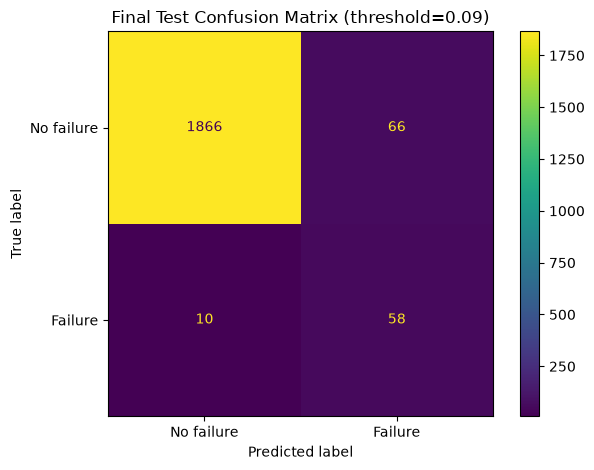

In [7]:
test_prob = pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

test_metrics = {
    "threshold": selected_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision_failure": precision_score(y_test, test_pred, zero_division=0),
    "recall_failure": recall_score(y_test, test_pred, zero_division=0),
    "f1_failure": f1_score(y_test, test_pred, zero_division=0),
    "pr_auc_average_precision": average_precision_score(y_test, test_prob),
    "true_negatives": int(tn),
    "false_alarms": int(fp),
    "missed_failures": int(fn),
    "detected_failures": int(tp),
}

display(pd.DataFrame([test_metrics]).round(4))
print(classification_report(
    y_test, test_pred,
    target_names=["No failure", "Failure"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No failure", "Failure"],
    values_format="d",
)
plt.title(f"Final Test Confusion Matrix (threshold={selected_threshold:.2f})")
plt.tight_layout()
plt.show()

## 8. Save the model, threshold, and metadata

We save the complete scikit-learn pipeline, including the fitted preprocessing and XGBoost model. The API can load this artifact and pass a DataFrame with the original feature names.

**Compatibility:** load joblib artifacts only from trusted sources and use compatible Python, scikit-learn, and XGBoost versions. The saved metadata records the versions used here.

In [8]:
import sklearn
import xgboost

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "p227_xgboost_pipeline.joblib"
metadata_path = MODEL_DIR / "model_metadata.json"
metrics_path = REPORT_DIR / "final_test_metrics.json"

joblib.dump(pipeline, model_path)

metadata = {
    "project": "P_227 - AI-Based Industrial Asset Risk Prediction Platform",
    "dataset": "AI4I 2020 Predictive Maintenance Dataset",
    "target": TARGET,
    "features": FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "algorithm": "XGBoostClassifier",
    "class_weighting": "none",
    "decision_threshold": selected_threshold,
    "threshold_selection_rule": (
        f"Recall >= {MIN_VALIDATION_RECALL:.2f} on validation; "
        "maximize precision, tie-break on higher threshold"
    ),
    "random_state": RANDOM_STATE,
    "split_sizes": {
        "train": int(len(X_train)),
        "validation": int(len(X_val)),
        "test": int(len(X_test)),
    },
    "versions": {
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
    },
    "status": "prototype_candidate",
    "limitations": [
        "AI4I is synthetic data and does not establish real-factory performance.",
        "The probability is not guaranteed to be calibrated as a real-world failure probability.",
        "Model does not automatically learn from unlabeled incoming telemetry.",
    ],
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print("Saved pipeline:", model_path)
print("Saved metadata:", metadata_path)
print("Saved final test metrics:", metrics_path)

Saved pipeline: C:\Users\Vinayak Mani Tripath\OneDrive\Desktop\Major_Project\P_227\models\p227_xgboost_pipeline.joblib
Saved metadata: C:\Users\Vinayak Mani Tripath\OneDrive\Desktop\Major_Project\P_227\models\model_metadata.json
Saved final test metrics: C:\Users\Vinayak Mani Tripath\OneDrive\Desktop\Major_Project\P_227\reports\final_test_metrics.json


## 9. Smoke-test the saved artifact with one example input

This verifies that the saved pipeline accepts raw feature columns and returns a probability. The example values are illustrative, and the prediction is not a real equipment diagnosis.

In [9]:
loaded_pipeline = joblib.load(model_path)

example_input = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 40.0,
    "Tool wear [min]": 100,
}])

example_probability = float(loaded_pipeline.predict_proba(example_input)[0, 1])
example_prediction = int(example_probability >= selected_threshold)

print({
    "failure_probability": round(example_probability, 4),
    "threshold": selected_threshold,
    "predicted_failure": example_prediction,
    "interpretation": "failure flag" if example_prediction else "no failure flag",
})

{'failure_probability': 0.0004, 'threshold': 0.09, 'predicted_failure': 0, 'interpretation': 'no failure flag'}


## 10. How this model connects to the complete P_227 application

```text
Historical AI4I CSV
    -> preprocessing + stratified train/validation/test split
    -> unweighted XGBoost pipeline
    -> validation-selected threshold
    -> saved pipeline + metadata
                      |
                      v
MQTT sensor simulator -> MQTT subscriber / FastAPI
                           -> validate six raw input fields
                           -> load saved pipeline
                           -> predict failure probability
                           -> apply saved threshold
                           -> store telemetry + prediction + alert in PostgreSQL
                           -> return result through API
                           -> Streamlit user dashboard
                           -> Grafana monitoring dashboard
```

### Deployment rules
- Keep the six input features and their names consistent between training and API inference.
- Treat `failure_probability` as a model score until calibrated and validated on representative real data.
- Store asset IDs and timestamps in the application database; these are operational metadata, not current model inputs.
- New telemetry alone is not a ground-truth label. Retraining requires verified outcomes, versioning, evaluation, and a controlled deployment.
- The initial model is a prototype candidate. Do not describe it as validated for real industrial safety decisions.